# Module 04: Physics-Based Vehicle Energy Model for What-If Analysis

## Why this notebook

The Elastic Net energy model of notebook 01 predicts trip energy consumption well (test
R² 0.837), but it is a statistical model of whole-trip averages. Speed, acceleration, weather and
route change together across trips (high-speed trips are also the warm summer trips), so its
coefficients share credit between correlated inputs. Several of them have signs that are not
physical: in that model, smoother driving or lower speed would *raise* the predicted energy use.
It can predict, but it cannot answer **"what if I drove differently?"**

This notebook builds a model that can: a **grey-box vehicle energy model** based on the standard
longitudinal driving-resistance equation, with a few physical constants fitted to the measured
battery power of the Munich trips.

## Model

For every second of a trip, the power at the wheels is

`P_wheel = (m·a + m·g·C_rr + m·g·grade + ½·ρ·C_dA·v²) · v`

and the power drawn from the battery is

`P_battery = P_wheel / η` when driving, `P_wheel · η_regen` when braking (regeneration),
`+ k_heat · P_heating + k_ac · P_aircon + P_aux`

| Constant | Meaning | Fitted? |
|---|---|---|
| `m` | effective mass (car, occupants, rotating parts) | yes |
| `C_dA` | drag coefficient × frontal area | yes |
| `C_rr` | rolling resistance coefficient | yes |
| `η`, `η_regen` | drivetrain efficiency when driving and when regenerating | yes |
| `P_aux` | constant auxiliary load (electronics, pumps) | yes |
| `k_heat`, `k_ac` | share of the logged heating / air-conditioning power drawn from the battery, per logging campaign (A and B trips) | yes |
| `g`, `ρ` | gravity 9.81 m/s², air density 1.2 kg/m³ | fixed |

Speed `v`, acceleration `a`, road grade and heating / AC power come from the 10 Hz telemetry.

## What the model is for

The what-if simulator changes the **speed profile** of a trip (smoother driving, lower or higher
speed) or the **heating / AC power** and recomputes the energy with this equation. Because every
term is physical, the effect of each change has the right direction and a physical size.

## Data and split

The 70 Munich trips of the TUM dataset, with the same 3 excluded trips and the same train/test
split as notebook 03 (`train_test_split(sorted(valid_trips), test_size=0.2, random_state=42)`):
53 trips to fit, 14 unseen trips to test.

## 1. Setup

In [1]:
import json
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Same data location convention as notebook 03; SPARKEV_M4_DATA overrides it
MODULE_DIR = Path(os.environ.get("SPARKEV_M4_DATA", Path.cwd()))
if not (MODULE_DIR / "Overview.xlsx").exists():
    MODULE_DIR = Path.cwd() / "module_01"
TRIP_FILES = sorted(list(MODULE_DIR.glob("TripA*.csv")) + list(MODULE_DIR.glob("TripB*.csv")))
assert len(TRIP_FILES) == 70

EXCLUDED_TRIPS = {"TripA31", "TripB04", "TripB09"}          # as in notebook 03
valid_trips = sorted({p.stem for p in TRIP_FILES} - EXCLUDED_TRIPS)
train_trips, test_trips = train_test_split(valid_trips, test_size=0.2, random_state=RANDOM_STATE)
train_trips, test_trips = sorted(train_trips), sorted(test_trips)

G, RHO = 9.81, 1.2
print(f"Valid trips: {len(valid_trips)} | fit: {len(train_trips)} | test: {len(test_trips)}")
print("Test trips:", test_trips)

Valid trips: 67 | fit: 53 | test: 14
Test trips: ['TripA01', 'TripA05', 'TripA06', 'TripA10', 'TripA13', 'TripA17', 'TripA26', 'TripA29', 'TripB07', 'TripB12', 'TripB17', 'TripB31', 'TripB33', 'TripB36']


## 2. Telemetry at 1 Hz

Each trip is averaged to one row per second. Battery power is `-voltage × current` (the car logs
discharge current as negative). Speed is lightly smoothed (3 s) before differentiating it into
acceleration; the road grade comes from the smoothed elevation (31 s) divided by the distance
travelled, clipped to ±15 %. The energy consumption of a trip is the integrated battery power
divided by the distance, the same quantity as the Module 4 target.

In [2]:
def load_trip(trip):
    d = pd.read_csv(MODULE_DIR / f"{trip}.csv", sep=";", encoding="cp1252")
    d.columns = d.columns.str.strip().str.replace("[km/h]]]", "[km/h]", regex=False)
    d["sec"] = np.floor(d["Time [s]"]).astype(int)
    d["heat_w"] = d.get("Heating Power CAN [kW]", 0) * 1000.0
    d["ac_w"] = d.get("AirCon Power [kW]", 0) * 1000.0
    d["p_batt"] = -d["Battery Voltage [V]"] * d["Battery Current [A]"]
    s = d.groupby("sec").agg(v=("Velocity [km/h]", "mean"), h=("Elevation [m]", "mean"),
                             p=("p_batt", "mean"), heat=("heat_w", "mean"),
                             ac=("ac_w", "mean")).reset_index()
    s["v"] = (s["v"] / 3.6).rolling(3, center=True, min_periods=1).mean()
    s["a"] = np.gradient(s["v"].values)
    dh = np.gradient(s["h"].rolling(31, center=True, min_periods=1).mean().values)
    s["grade"] = np.clip(np.where(s["v"] > 1.0, dh / np.maximum(s["v"], 1e-6), 0.0), -0.15, 0.15)
    s["is_b"] = float(trip.startswith("TripB"))
    return s


data = {t: load_trip(t) for t in valid_trips}


def measured_kwh_per_km(s):
    return s["p"].sum() / 3.6e6 / (s["v"].sum() / 1000)


summary = pd.DataFrame({
    "km": [data[t]["v"].sum() / 1000 for t in valid_trips],
    "minutes": [len(data[t]) / 60 for t in valid_trips],
    "kWh_per_km": [measured_kwh_per_km(data[t]) for t in valid_trips],
}, index=valid_trips)
print(f"{len(data)} trips, {sum(len(s) for s in data.values()):,} seconds of driving")
summary.describe().round(3)

67 trips, 99,752 seconds of driving


,km,minutes,kWh_per_km
count,67.000,67.000,67.000
mean,18.971,24.814,0.165
std,11.015,12.235,0.035
min,2.793,5.917,0.096
25%,12.369,16.558,0.138
50%,16.425,23.383,0.165
75%,19.309,29.725,0.191
max,60.975,63.700,0.233


## 3. Fit the physical constants

All constants are fitted together by bounded nonlinear least squares on the second-by-second
battery power of the 53 fitting trips. The bounds keep every constant physically meaningful.

In [3]:
PARAM_NAMES = ["m_kg", "CdA_m2", "Crr", "eta", "eta_regen", "P_aux_W",
               "k_heat_A", "k_ac_A", "k_heat_B", "k_ac_B"]
X0 = [1300, 0.7, 0.01, 0.9, 0.7, 500, 1.0, 0.5, 1.0, 0.5]
LOWER = [1150, 0.4, 0.004, 0.70, 0.30, 0, 0.0, 0.0, 0.0, 0.0]
UPPER = [1700, 1.0, 0.020, 0.98, 0.95, 3000, 1.5, 1.5, 1.5, 1.5]


def battery_power(theta, v, a, grade, heat, ac, is_b):
    m, cda, crr, eta, eta_r, p_aux, kh_a, kac_a, kh_b, kac_b = theta
    force = m * a + m * G * crr * (v > 0.1) + m * G * grade + 0.5 * RHO * cda * v ** 2
    p_wheel = force * v
    p_drive = np.where(p_wheel >= 0, p_wheel / eta, p_wheel * eta_r)
    k_heat = is_b * kh_b + (1 - is_b) * kh_a
    k_ac = is_b * kac_b + (1 - is_b) * kac_a
    return p_drive + k_heat * heat + k_ac * ac + p_aux


def predict_power(theta, s):
    return battery_power(theta, s["v"].values, s["a"].values, s["grade"].values,
                         s["heat"].values, s["ac"].values, s["is_b"].values)


fit_rows = pd.concat([data[t] for t in train_trips], ignore_index=True)
result = least_squares(lambda th: (predict_power(th, fit_rows) - fit_rows["p"].values) / 1000,
                       X0, bounds=(LOWER, UPPER))
theta = result.x
params = pd.Series(theta, index=PARAM_NAMES)
params.round(4)

m_kg         1547.3934
CdA_m2          0.5390
Crr             0.0114
eta             0.8295
eta_regen       0.8970
P_aux_W       657.8921
k_heat_A        0.4551
k_ac_A          0.2396
k_heat_B        1.2253
k_ac_B          1.5000
dtype: float64

**Are the constants physical?** For a BMW i3 (the car in this dataset), published figures are a
drag coefficient of about 0.29 and a frontal area of about 2.4 m² (C_dA ≈ 0.7 m²), an empty mass
of roughly 1.2 to 1.35 t depending on the version, and rolling resistance coefficients of
0.008 to 0.015 are typical for passenger-car tyres.

- **Mass ~1.55 t** includes occupants, load and the inertia of rotating parts, so it is expected
  to be above the empty mass.
- **C_rr ~0.011** is in the typical range.
- **C_dA ~0.54 m²** is lower than the published 0.7 m². Part of the aerodynamic drag is absorbed
  by the other constants, and the wind and the exact air density are not measured. The fitted value
  is the one that best explains this car's measured power.
- **η ~0.83 and η_regen ~0.90** are plausible battery-to-wheel efficiencies.
- **k_ac (A trips) is far below 1:** on the summer trips the logged air-conditioning power is much
  larger than what the battery actually supplies (on one trip it exceeds the car's whole energy
  use). The climate signals of the two logging campaigns (A: 28 columns, B: 48 columns) do not
  mean the same thing, which is why they get separate factors.

## 4. Validation on the 14 unseen test trips

In [4]:
def trip_kwh_per_km(theta, s):
    return predict_power(theta, s).sum() / 3.6e6 / (s["v"].sum() / 1000)


test_rows = pd.concat([data[t] for t in test_trips], ignore_index=True)
print("Second-by-second battery power, R²")
print(f"  fitting trips : {r2_score(fit_rows['p'], predict_power(theta, fit_rows)):.3f}")
print(f"  unseen trips  : {r2_score(test_rows['p'], predict_power(theta, test_rows)):.3f}")

rows = []
for name, trips in [("all test trips", test_trips),
                    ("winter trips (B)", [t for t in test_trips if t.startswith("TripB")]),
                    ("summer trips (A)", [t for t in test_trips if t.startswith("TripA")])]:
    y = [measured_kwh_per_km(data[t]) for t in trips]
    p = [trip_kwh_per_km(theta, data[t]) for t in trips]
    rows.append(dict(trips=name, n=len(trips), R2=r2_score(y, p), MAE_kWh_per_km=mean_absolute_error(y, p)))
trip_validation = pd.DataFrame(rows).set_index("trips")
print("\nWhole-trip energy consumption (kWh/km)")
trip_validation.round(4)

Second-by-second battery power, R²
  fitting trips : 0.903
  unseen trips  : 0.878



Whole-trip energy consumption (kWh/km)


,n,R2,MAE_kWh_per_km
trips,,,
all test trips,14,0.5337,0.0147
winter trips (B),6,0.9048,0.0061
summer trips (A),8,-0.3279,0.0212


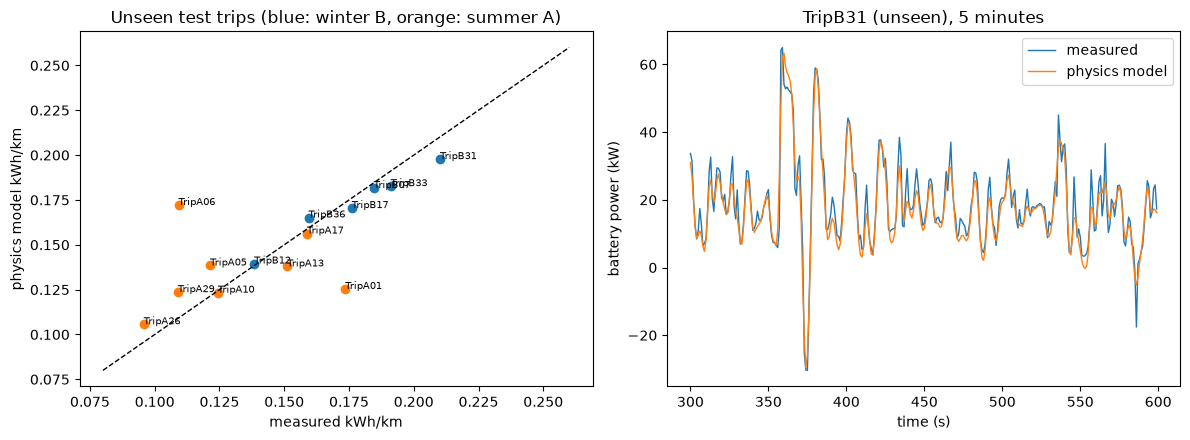

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for t in test_trips:
    y, p = measured_kwh_per_km(data[t]), trip_kwh_per_km(theta, data[t])
    axes[0].scatter(y, p, color="#1f77b4" if t.startswith("TripB") else "#ff7f0e")
    axes[0].annotate(t, (y, p), fontsize=7)
lims = [0.08, 0.26]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("measured kWh/km"); axes[0].set_ylabel("physics model kWh/km")
axes[0].set_title("Unseen test trips (blue: winter B, orange: summer A)")

s = data["TripB31"]
window = slice(300, 600)
axes[1].plot(s["sec"].values[window], s["p"].values[window] / 1000, label="measured", lw=1)
axes[1].plot(s["sec"].values[window], predict_power(theta, s)[window] / 1000, label="physics model", lw=1)
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("battery power (kW)")
axes[1].set_title("TripB31 (unseen), 5 minutes")
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the validation.**

- **Second by second**, the model explains most of the measured battery power on trips it never
  saw (R² above). This is the part the what-if simulator relies on: how speed, acceleration,
  braking and climbing turn into battery power.
- **Whole trips in winter (B trips)**, where the heater is logged reliably, the energy
  consumption is predicted with a small error.
- **Whole trips in summer (A trips)** are predicted poorly. The driving part is the same physics;
  the error comes from the climate signals of that logging campaign, which do not match the
  power the battery supplies. No model can recover a quantity that is not measured correctly.

As a pure predictor of trip consumption, the Elastic Net of notebooks 01 and 02 stays better
(test R² 0.837 on these same 14 trips): it uses whole-trip measurements such as the mean
battery current. The physics model is not meant to replace it. It is used where the Elastic Net
cannot be used: to estimate the effect of driving differently.

## 5. What-if functions

A trip's 1 Hz speed profile is changed and the energy is recomputed with the fitted model:

- **Driving style** `style`: the speed profile is split into a 31 s moving average (the traffic
  flow) and the fluctuations around it (accelerating and braking). The fluctuations are multiplied
  by `style`: 0.7 = 30 % gentler accelerating and braking at the same average speed.
- **Speed** `speed`: all speeds are multiplied by `speed`. The same distance is then driven in
  `1 / speed` of the time, so time-based loads (auxiliary, heating) shrink at higher speed while
  air drag grows with the square of the speed.
- **Climate** `climate`: heating and air-conditioning power are multiplied by `climate`.

The road (distance and grade) stays the same.

In [6]:
def simulate_kwh_per_km(theta, s, style=1.0, speed=1.0, climate=1.0):
    v = s["v"].values
    trend = pd.Series(v).rolling(31, center=True, min_periods=1).mean().values
    v_new = np.clip(trend + style * (v - trend), 0, None) * speed
    dt = 1.0 / speed
    a_new = np.gradient(v_new, dt)
    power = battery_power(theta, v_new, a_new, s["grade"].values,
                          climate * s["heat"].values, climate * s["ac"].values, s["is_b"].values)
    km = v_new.sum() * dt / 1000
    return power.sum() * dt / 3.6e6 / km


# Sanity check: with no change the simulation reproduces the fitted model
for t in ["TripB31", "TripA29"]:
    assert abs(simulate_kwh_per_km(theta, data[t]) - trip_kwh_per_km(theta, data[t])) < 1e-3

DEMO_TRIPS = {17: "TripB31", 24: "TripA29"}      # the demo trips of the ESP32 / dashboard
scenarios = [("as driven", 1.0, 1.0, 1.0),
             ("smoother driving (style 0.7)", 0.7, 1.0, 1.0),
             ("more aggressive (style 1.3)", 1.3, 1.0, 1.0),
             ("10% slower", 1.0, 0.9, 1.0),
             ("10% faster", 1.0, 1.1, 1.0),
             ("half the heating / AC", 1.0, 1.0, 0.5)]
table = pd.DataFrame({
    f"driver {d} ({t})": [simulate_kwh_per_km(theta, data[t], st, sp, cl) for _, st, sp, cl in scenarios]
    for d, t in DEMO_TRIPS.items()
}, index=[name for name, *_ in scenarios])
print("Energy consumption (kWh/km) under each scenario")
table.round(4)

Energy consumption (kWh/km) under each scenario


,driver 17 (TripB31),driver 24 (TripA29)
as driven,0.1978,0.1236
smoother driving (style 0.7),0.1949,0.1183
more aggressive (style 1.3),0.2011,0.1292
10% slower,0.1926,0.1167
10% faster,0.2058,0.1318
half the heating / AC,0.1683,0.1227


In [7]:
# Effect of each change across all 67 trips (median change in kWh/km)
effects = {}
for name, st, sp, cl in scenarios[1:]:
    effects[name] = np.median([simulate_kwh_per_km(theta, data[t], st, sp, cl)
                               - simulate_kwh_per_km(theta, data[t]) for t in valid_trips])
pd.Series(effects, name="median change (kWh/km)").round(4)

smoother driving (style 0.7)   -0.0045
more aggressive (style 1.3)     0.0048
10% slower                     -0.0062
10% faster                      0.0085
half the heating / AC          -0.0153
Name: median change (kWh/km), dtype: float64

## 6. Export for the backend

In [8]:
# Fitted constants and the 1 Hz profiles of the two demo trips, used by
# backend/model4_physics.py for the What-If Simulator
profiles = {}
for driver, trip in DEMO_TRIPS.items():
    s = data[trip]
    profiles[str(driver)] = dict(trip=trip, is_b=float(s["is_b"].iloc[0]),
                                 v=s["v"].round(4).tolist(), grade=s["grade"].round(5).tolist(),
                                 heat=s["heat"].round(1).tolist(), ac=s["ac"].round(1).tolist())
export = dict(
    description="Grey-box vehicle energy model, notebooks/module4_energy_and_soc/04_physics_energy_model.ipynb",
    constants=dict(g=G, rho=RHO, trend_window_s=31),
    params=dict(zip(PARAM_NAMES, map(float, theta))),
    validation=dict(power_r2_test=float(r2_score(test_rows["p"], predict_power(theta, test_rows))),
                    trip_r2_test_winter=float(trip_validation.loc["winter trips (B)", "R2"]),
                    trip_mae_test_winter=float(trip_validation.loc["winter trips (B)", "MAE_kWh_per_km"])),
    demo_profiles=profiles,
)
out_path = Path("..") / ".." / "models" / "model4_physics_energy.json"
json.dump(export, open(out_path, "w"))
print("written:", out_path, f"({out_path.stat().st_size / 1024:.0f} KB)")

written: ../../models/model4_physics_energy.json (67 KB)


## 7. Findings

The numbers below are from the run shown in this notebook.

1. **The physics holds on unseen trips.** With 10 fitted constants (6 physical and 4
   climate-signal factors), the model explains 90 % of the second-by-second battery power on the
   fitting trips and **88 % on the 14 unseen trips**. The fitted constants are physically
   plausible: effective mass 1.55 t, C_rr 0.011, drivetrain efficiency 0.83, regeneration 0.90,
   auxiliary load 0.66 kW.

2. **Whole-trip energy is accurate where the climate signals are reliable.** On the winter test
   trips (B) the trip consumption is predicted with R² 0.90 and an error of 0.006 kWh/km. On the
   summer trips (A) the logged air-conditioning and heating power does not match what the battery
   supplies, so whole-trip predictions there are poor (R² -0.33). The driving physics is the same
   on both; the problem is the logged climate power of that campaign.

3. **The what-if effects have the physically correct direction and a plausible size** (median
   over all 67 trips): smoother driving -0.0045 kWh/km (about 3 %), more aggressive +0.0048,
   10 % slower -0.0062, 10 % faster +0.0085 (air drag grows with the square of the speed), half
   the heating / AC -0.015. In the Elastic Net, smoother or slower driving would have raised the
   prediction.

4. **Division of labour.** The Elastic Net (notebooks 01 and 02) remains the model for predicting
   a trip's consumption (test R² 0.837, also used on the ESP32). This physics model is used by
   the What-If Simulator to estimate how a change in driving or climate use changes it.

### Limitations

- One car, one driver: the constants describe this BMW i3 and its usual load.
- `C_dA` (0.54 m²) is below the published value (about 0.7 m²); wind, exact air density and the
  correlation with the other constants are absorbed in the fit.
- `k_ac_B` sits at its upper bound: air conditioning is almost never used on the winter trips, so
  the data cannot identify it. It has almost no effect on any winter trip.
- The driving-style change scales the speed fluctuations around a 31 s moving average. Real
  smoother driving can also change the route timing and traffic interaction, which the model does
  not capture.
- Battery temperature effects on efficiency are not modelled.